# Batch, Stochastic và Mini-batch Gradient Descent

*Bài 5, mục 5.2 và 5.3.1, Bước 2.* Một hàm chung với tham số `batch_size`: bằng $N$ là Batch GD, bằng 1 là SGD, ở giữa là Mini-batch GD.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(2)
X = np.random.rand(1000)                       # x trong [0, 1)
y = 4 + 3 * X + .2 * np.random.randn(1000)     # y = 4 + 3x + nhiễu
Xbar = np.column_stack([np.ones(len(X)), X])   # mỗi hàng [1, x_i]


def loss(w, Xb, y):
    return np.sum((Xb @ w - y)**2) / (2 * len(y))


def grad(w, Xb, y):
    return Xb.T @ (Xb @ w - y) / len(y)


def minibatch_gd(Xb, y, eta, batch_size, so_epoch, w_init=None, seed=0):
    rng = np.random.default_rng(seed)
    N = len(y)
    w = np.zeros(Xb.shape[1]) if w_init is None else w_init.copy()
    lich_su = [loss(w, Xb, y)]                    # loss trên toàn bộ dữ liệu sau mỗi epoch
    for epoch in range(so_epoch):
        thu_tu = rng.permutation(N)               # xáo trộn dữ liệu mỗi epoch
        for s in range(0, N, batch_size):
            B = thu_tu[s:s + batch_size]          # chỉ số các mẫu trong mini-batch
            w = w - eta * grad(w, Xb[B], y[B])    # gradient trung bình trên mini-batch
        lich_su.append(loss(w, Xb, y))
    return w, lich_su


w_ols = np.linalg.pinv(Xbar.T @ Xbar) @ Xbar.T @ y
print('OLS: w = %s, loss nhỏ nhất = %.4f' % (w_ols.round(4), loss(w_ols, Xbar, y)))

OLS: w = [4.0072 2.9823], loss nhỏ nhất = 0.0189


## So sánh ba biến thể trong 20 epoch

Batch      cập nhật/epoch =    1, w = [4.1089 2.787 ], loss sau epoch 1, 2, 20: [0.332  0.0548 0.0205]


SGD        cập nhật/epoch = 1000, w = [4.0209 2.9716], loss sau epoch 1, 2, 20: [0.0217 0.019  0.0189]
Mini-batch cập nhật/epoch =   32, w = [4.0349 2.9859], loss sau epoch 1, 2, 20: [0.0282 0.02   0.0193]


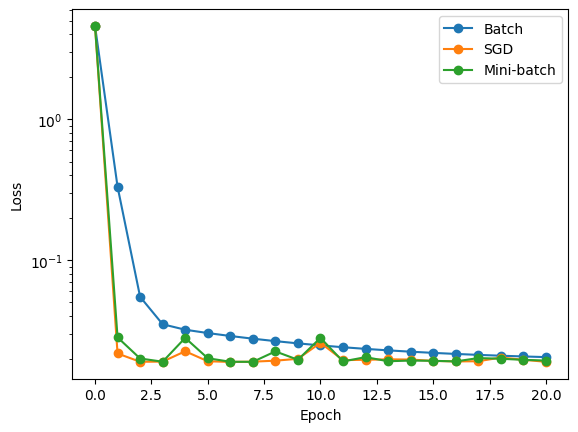

In [2]:
w0 = np.array([2., 1.])
for ten, bs, eta in [('Batch', 1000, 1.0), ('SGD', 1, 0.05), ('Mini-batch', 32, 0.5)]:
    w, lich_su = minibatch_gd(Xbar, y, eta, bs, so_epoch=20, w_init=w0)
    print('%-10s cập nhật/epoch = %4d, w = %s, loss sau epoch 1, 2, 20: %s' %
          (ten, int(np.ceil(1000 / bs)), w.round(4),
           np.round([lich_su[1], lich_su[2], lich_su[20]], 4)))
    plt.plot(lich_su, 'o-', label=ten)
plt.yscale('log'); plt.xlabel('Epoch'); plt.ylabel('Loss')
plt.legend(); plt.show()

Tính theo epoch, SGD và Mini-batch giảm nhanh hơn Batch GD rất nhiều (vì cập nhật nhiều lần mỗi epoch), nhưng dao động quanh cực tiểu.